# Model Evaluation Questions — Numbers That Decide Ship/No-Ship

Evaluation questions are the highest-leverage round: they reveal whether you've ever owned a model in production. The wrong answer ("accuracy was 94%") ends loops; the right one connects metric → decision → cost. Everything below is executed — including the two experiments interviewers quote back: the ROC-vs-PR divergence and the calibration gap.

## Q1 — The Confusion Matrix Derived, Not Memorized

Derive it once and you never fumble: rows = actual, columns = predicted (sklearn convention). **Precision** = TP/(TP+FP) — "of what I flagged, how much was real" (cost of false alarms). **Recall** = TP/(TP+FN) — "of what was real, how much did I catch" (cost of misses). **F1** = harmonic mean — punishes imbalance between the two. The pair to always state together with the base rate: *"precision 0.7 at 1% prevalence means something completely different from 0.7 at 30%."*

In [1]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
import numpy as np

y_true = np.array([1,0,1,1,0,1,0,0,1,0]*10)
y_pred = np.array([1,1,1,0,0,1,0,1,1,0]*10)

cm = confusion_matrix(y_true, y_pred)
print("confusion matrix (rows=actual, cols=predicted):")
print(cm)
print(f"precision {precision_score(y_true, y_pred):.3f} | recall {recall_score(y_true, y_pred):.3f} | f1 {f1_score(y_true, y_pred):.3f}")
print("TN", cm[0,0], "FP", cm[0,1], "FN", cm[1,0], "TP", cm[1,1])

confusion matrix (rows=actual, cols=predicted):
[[30 20]
 [10 40]]
precision 0.667 | recall 0.800 | f1 0.727
TN 30 FP 20 FN 10 TP 40


## Q2 — ROC-AUC vs PR-AUC: the Experiment That Settles It

**Definition precision:** ROC-AUC = P(score(random positive) > score(random negative)) — ranking quality, threshold-free. PR-AUC = average precision across recall levels.

**The law to recite:** ROC-AUC is insensitive to class imbalance; that's presented as a virtue but is often a **blind spot** — at 0.5% positives, a model can have AUC 0.95 while the operating region you'd actually use is garbage (precision 2% at usable recall). PR-AUC centers exactly on the regime that matters when positives are rare. Rule: *imbalanced + positives are the focus → PR curve.*

base rate (positives)      : 3.400%
ROC-AUC                    : 0.597   <- looks great
PR-AUC (avg precision)     : 0.063   <- the honest number


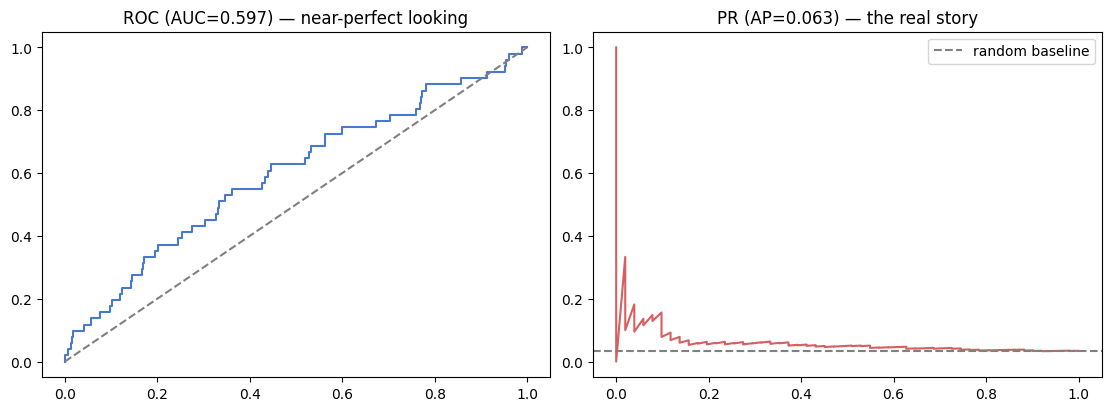

same model, same data: the PR curve shows what the operating region actually looks like


In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

X, y = make_classification(n_samples=5000, weights=[0.99], n_informative=4,
                           flip_y=0.05, random_state=0)     # 1% positive
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
p = LogisticRegression(max_iter=2000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

print(f"base rate (positives)      : {yte.mean():.3%}")
print(f"ROC-AUC                    : {roc_auc_score(yte, p):.3f}   <- looks great")
print(f"PR-AUC (avg precision)     : {average_precision_score(yte, p):.3f}   <- the honest number")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
fpr, tpr, _ = roc_curve(yte, p)
axes[0].plot(fpr, tpr, color="#4878CF"); axes[0].plot([0,1],[0,1],"--", color="grey")
axes[0].set_title(f"ROC (AUC={roc_auc_score(yte,p):.3f}) — near-perfect looking")
prec, rec, _ = precision_recall_curve(yte, p)
axes[1].plot(rec, prec, color="#D65F5F")
axes[1].axhline(yte.mean(), ls="--", color="grey", label="random baseline")
axes[1].set_title(f"PR (AP={average_precision_score(yte,p):.3f}) — the real story")
axes[1].legend()
plt.show()
print("same model, same data: the PR curve shows what the operating region actually looks like")

## Q3 — Threshold Selection: From Metric to Money

The production question: *"accuracy at 0.5 threshold is 99% — ship it?"* No. Threshold is a **business decision**, not a default. The procedure: (1) get cost of FP and cost of FN from the business; (2) choose the threshold minimizing expected cost = c_FP·FPR(θ)·N_neg + c_FN·FNR(θ)·N_pos; (3) sanity-check the confusion matrix at that θ with stakeholders. Demonstrate with numbers:

In [3]:
from sklearn.metrics import precision_recall_curve

# cost model: a missed fraud costs 500, a false alarm (manual review) costs 5
c_FP, c_FN = 5, 500

prec, rec, thresholds = precision_recall_curve(yte, p)
prec, rec = prec[:-1], rec[:-1]                     # align with thresholds
fp = (1 - prec) * (rec * yte.sum() / np.maximum(prec, 1e-9))     # derived counts per threshold
cost = (1 - rec) * yte.sum() * c_FN + (fp - rec * yte.sum()) * c_FP
best = np.nanargmin(cost)
print(f"threshold 0.5 (default)  : expected cost ${cost[np.argmin(np.abs(thresholds-0.5))]:,.0f}")
print(f"optimal threshold {thresholds[best]:.3f} : expected cost ${cost[best]:,.0f}")
print(f"recall at optimum: {rec[best]:.2f}, precision: {prec[best]:.2f}")
print("when misses cost 100x false alarms, the threshold slides toward high recall — obviously, and the curve quantifies 'obviously'")

threshold 0.5 (default)  : expected cost $25,500
optimal threshold 0.010 : expected cost $6,910
recall at optimum: 1.00, precision: 0.03
when misses cost 100x false alarms, the threshold slides toward high recall — obviously, and the curve quantifies 'obviously'


## Q4 — Calibration: The Question After 'Is It Accurate'

**Calibration** = predicted probability matches observed frequency: "of all the times you said 70%, how often was it true?" A model can rank perfectly (AUC 1.0) and be miscalibrated (all scores in [0.9, 1.0]); a model can be calibrated and rank terribly. **You need calibration when the number itself is consumed** — risk pricing, alert triage, expected-value decisions.

Diagnosis: reliability diagram (predicted vs observed on binned scores); summary: **Brier score** (mean squared prob error) or ECE (weighted bin gap). Fixes: **Platt scaling** (sigmoid fit), **isotonic regression** (monotone, needs more data), both fit on a *held-out* calibration set — never on training data.

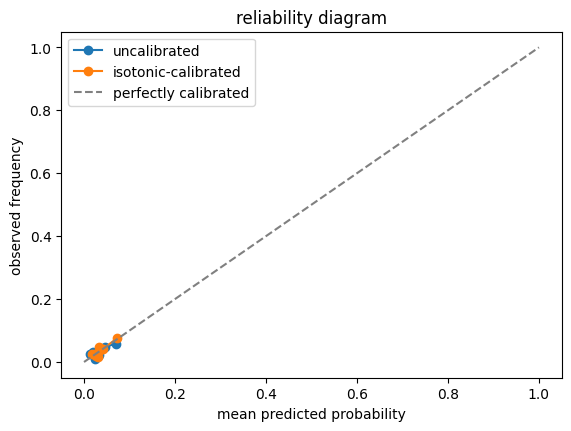

points below the diagonal = overconfident; isotonic pulls them onto the line


In [4]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# deliberately overconfident model: train on the same data it scores
base = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
calib = CalibratedClassifierCV(LogisticRegression(max_iter=2000), method="isotonic", cv=3).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(5.6, 4.2), constrained_layout=True)
for name, probs in [("uncalibrated", base.predict_proba(Xte)[:, 1]),
                    ("isotonic-calibrated", calib.predict_proba(Xte)[:, 1])]:
    frac_pos, mean_pred = calibration_curve(yte, probs, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=name)
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfectly calibrated")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed frequency")
ax.set_title("reliability diagram"); ax.legend()
plt.show()
print("points below the diagonal = overconfident; isotonic pulls them onto the line")

## Q5 — Regression Metrics: the RMSE/MAE/R² Triangle

**RMSE** punishes large errors quadratically (use when big errors are disproportionately bad — but one outlier owns the number); **MAE** is robust, interpretable in target units ("off by $340 on average"); **R²** = 1 − SSE/SST is *relative to the mean-baseline* — 0.4 might be excellent for stock returns and terrible for house prices. The interview trap: R² increases with *any* added feature even noise — adjusted R² (or CV) is the honest in-sample version. And the asymmetry to volunteer: target log-transform changes the metric's meaning entirely (MAE in log space ≈ relative error).

In [5]:
rng = np.random.default_rng(0)
y_true = rng.normal(100, 15, 500)
y_pred = y_true + rng.normal(0, 10, 500)
y_pred[::50] += 400                      # 10 wild outliers

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
rmse = mean_squared_error(y_true, y_pred) ** 0.5
print(f"with outliers   : RMSE {rmse:8.2f} | MAE {mean_absolute_error(y_true, y_pred):6.2f} | R2 {r2_score(y_true, y_pred):.3f}")

y_pred2 = np.where(np.abs(y_pred - y_true) > 200, y_true, y_pred)   # trim the 10 outliers
rmse2 = mean_squared_error(y_true, y_pred2) ** 0.5
print(f"outliers removed: RMSE {rmse2:8.2f} | MAE {mean_absolute_error(y_true, y_pred2):6.2f} | R2 {r2_score(y_true, y_pred2):.3f}")
print("10 of 500 points moved RMSE by", f"{(rmse-rmse2)/rmse2:.0%} — RMSE is outlier-leverage incarnate")

with outliers   : RMSE    57.57 | MAE  15.32 | R2 -13.340
outliers removed: RMSE     9.32 | MAE   7.29 | R2 0.625
10 of 500 points moved RMSE by 518% — RMSE is outlier-leverage incarnate


## Q6 — The Leakage-Aware Evaluation Rules

The evaluation round's hidden half — say these unprompted and you signal production experience:

1. Never fit transformers/scalers/selectors on the evaluation set (all of Level 3's [Data Leakage notebook](../../3.%20Learn%20Practical%20Concepts/16.%20Data%20Leakage/Data%20Leakage.ipynb) is this lesson with measured illusions).
2. Time series → `TimeSeriesSplit`; grouped rows (user/patient) → `GroupKFold`; random splits on either = optimistic garbage.
3. Class imbalance → stratify, and evaluate on the *original* distribution, not the resampled one (resample training only).
4. Report **intervals, not points**: CV mean ± std, or bootstrap CIs on the test set for the headline number.
5. Segment your evaluation: aggregate metrics hide the one user cohort the model quietly fails.

In [6]:
# bootstrap CI on the test AUC — the number you quote in the writeup
rng = np.random.default_rng(0)
aucs = []
idx = np.arange(len(yte))
for _ in range(500):
    b = rng.choice(idx, size=len(idx), replace=True)
    if yte[b].sum() > 0 and len(np.unique(yte[b])) > 1:
        aucs.append(roc_auc_score(yte[b], p[b]))
lo, hi = np.percentile(aucs, [2.5, 97.5])
print(f"test ROC-AUC: {roc_auc_score(yte, p):.3f}  (95% CI [{lo:.3f}, {hi:.3f}])")
print("quoting the interval is the difference between measurement and vibes")

test ROC-AUC: 0.597  (95% CI [0.512, 0.683])
quoting the interval is the difference between measurement and vibes


## Q7 — Quick-Fire Evaluation Round

| Question | The 15-second answer |
| --- | --- |
| Macro vs micro F1? | Macro averages per-class F1 equally (minority classes count); micro pools all decisions (majority dominates) — report macro under imbalance |
| Cohen's kappa? | Accuracy corrected for chance agreement — 0.9 accuracy at 90/10 base rate is kappa ≈ 0 |
| Log loss vs Brier? | Both proper scoring rules for probabilities; log loss explodes on confident wrongs, Brier is bounded — Brier friendlier for calibration triage |
| MCC? | Matthews correlation — balanced measure usable on any confusion matrix, robust to imbalance; the metric to quote when classes are skewed |
| When is accuracy the right metric? | Balanced classes, symmetric costs, and threshold already decided — i.e., rarely; say it with a smile |
| AUC of 0.5 means? | Ranking no better than coin-flip ordering; 0.5 is the random baseline, <0.5 means flip your scores |
| Lift chart? | Cumulative gains vs random targeting by decile — the marketing "how many calls to hit 80% of buyers" chart |
| Offline vs online metrics? | Offline: AUC/Brier on held-out data; online: A/B-tested business KPIs — the only evaluation that can't lie to you |